# ML Model with actual goals

In [16]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import xgboost as xgb
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [17]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def calc_mae(y_pred, y):
    mae = 0.0
    for pred, actual_value in zip(y_pred, y):
        if type(pred) == list:
            mae += np.abs((float(pred[0]) - float(actual_value)))
        else:
            mae += np.abs((float(pred) - float(actual_value)))
    return mae / len(y)



In [18]:
df_matches = pd.read_csv('matches_ac.csv', sep=';')

df_matches["is_eng"] = df_matches["country"].apply(lambda x: 1 if x == "ENG" else 0)
df_matches["is_esp"] = df_matches["country"].apply(lambda x: 1 if x == "ESP" else 0)
df_matches["is_fra"] = df_matches["country"].apply(lambda x: 1 if x == "FRA" else 0)
df_matches["is_ger"] = df_matches["country"].apply(lambda x: 1 if x == "GER" else 0)
df_matches["is_ita"] = df_matches["country"].apply(lambda x: 1 if x == "ITA" else 0)

all_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_chancediff", "at_curr_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_curr_chanceamount", "at_curr_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value", "at_market_value",
    "ht_market_value_ln", "at_market_value_ln",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]


ga_feature_set_heuer_country = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_feature_set_heuer_country = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff", 
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness", 
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

ga_feature_set_heuer = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_feature_set_heuer = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff", 
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness", 
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]

ga_selection = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_selection = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]
                  
ga_label = ["actual_goalamount"]
gd_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_last_year_xg_amount,xg_amount,xg_diff,actual_goalamount,actual_goaldiff,is_eng,is_esp,is_fra,is_ger,is_ita
0,ENG,14,1,Queens Park Rangers,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,3.018240,0.783100,1,-1,1,0,0,0,0
1,ENG,14,1,Newcastle,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.446113,-0.514947,2,-2,1,0,0,0,0
2,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.501101,-1.758819,4,-2,1,0,0,0,0
3,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.712261,1.395959,3,1,1,0,0,0,0
4,ENG,14,1,West Ham,Tottenham,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.870160,0.836040,1,-1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,0.959903,0.585014,0.537046,0,0,0,0,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,1.172081,0.370430,0.221648,0,0,0,0,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,1.795735,2.737759,-0.858041,5,1,0,0,0,0,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,1.370037,4.515770,0.970270,3,1,0,0,0,0,1


## Data split

In [19]:
df_training, df_testing = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")


## Remove outliers

In [20]:
df_training_cleansed = df_training.query(
    "actual_goalamount <= 8 and actual_goaldiff <= 6").copy()


## XG Boost baseline

In [21]:
ga_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

gd_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

ga_model.fit(df_training[all_features], df_training[ga_label])
gd_model.fit(df_training[all_features], df_training[gd_label])

ga_abs_error = calc_mae(ga_model.predict(df_testing[all_features]), df_testing[ga_label].values)
gd_abs_error = calc_mae(gd_model.predict(
    df_testing[all_features]), df_testing[gd_label].values)

print("XGBoost regressor MAE goalamount:", ga_abs_error)
print("XGBoost regressor MAE goaldifference:", gd_abs_error)


XGBoost regressor MAE goalamount: 1.3136416318513215
XGBoost regressor MAE goaldifference: 1.26236267329951


## Model selection

In [22]:
class GeneralModel:
    def __init__(self):
        self.model = LinearRegression() 

    def fit(self, df, features, label):
        self.model.fit(df[features], df[label])

    def predict(self, df, features):
        return self.model.predict(df[features])

    def predict_single(self, row, features):
        return self.model.predict([row[features]])[0][0]

    def print_weights(self):
        print("General model weights:")
        print(self.model.coef_ , self.model.intercept_)


class WeightsPerMatchnumberModel:
    def __init__(self):
        self.models = []

    def fit(self, df, features, label):
        for i in range(1, 39):
            matchnumber_df = df.query(f"matchnumber == {i}")
            self.models.append(LinearRegression().fit(matchnumber_df[features],
                               matchnumber_df[label]))

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            preds.append(
                self.models[row["matchnumber"]-1].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        return self.models[row["matchnumber"]-1].predict([row[features]])[0]

    def print_weights(self):
        print("Weights per matchnum model weights:")
        for model in self.models:
            print(model.coef_ , model.intercept_)


class SectionedModel:
    def __init__(self):
        self.models = [LinearRegression(), LinearRegression(),
                       LinearRegression()]

    def fit(self, df, features, label):
        first_df = df.query(f"(country == 'GER' and matchnumber < 18) or (country != 'GER' and matchnumber < 20)")
        second_df = df.query(
            f"(country == 'GER' and matchnumber >= 18 and matchnumber < 31) or (country != 'GER' and matchnumber >= 20 and matchnumber < 35)")
        third_df = df.query(
            f"(country == 'GER' and matchnumber >= 31) or (country != 'GER' and matchnumber >= 35)")
        if not first_df.empty:
            self.models[0].fit(first_df[features], first_df[label])
        else:
            self.models[0].fit([np.ones(len(features))], [[1]])
        if not second_df.empty:
            self.models[1].fit(second_df[features], second_df[label])
        else:
            self.models[1].fit([np.ones(len(features))], [[1]])
        if not third_df.empty:
            self.models[2].fit(third_df[features], third_df[label])
        else:
            self.models[2].fit([np.ones(len(features))], [[1]])
        

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
                preds.append(self.models[0].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
                preds.append(self.models[1].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
                preds.append(self.models[2].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
            return self.models[0].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
            return self.models[1].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
            return self.models[2].predict([row[features]])[0][0]

    def print_weights(self):
        print("Sectioned model weights:")
        for model in self.models:
            print(model.coef_ , model.intercept_)


## K-Fold-Crossvalidation

In [23]:
# Validate over:
# Feature selection (3)
# general weights; weights per matchnumber; weights for first seasonhalf, second and last 4
# Train-Valid split per season (4)
do_crossvalidation = False

if do_crossvalidation:
    #for data_name, train_df in zip(["full", "cleansed"], [df_training, df_training_cleansed]):
    for data_name, train_df in zip(["cleansed"], [df_training_cleansed]):
        for feature_set_name, feature_set in zip(["all", "heuer", "heuer_country", "selection"], [(all_features, all_features), (ga_feature_set_heuer, gd_feature_set_heuer), (ga_feature_set_heuer_country, gd_feature_set_heuer_country), (ga_selection, gd_selection)]):
            for weight_set_name in ["general", "per_match_no", "sectioned"]:
                ga_validation_error, gd_validation_error = 0, 0
                for season in range(14,18):
                    train_data, valid_data = train_df.query(
                        f"season != {season}"), train_df.query(f"season == {season}")

                    if weight_set_name == "general":
                        ga_model, gd_model = GeneralModel(), GeneralModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "per_match_no":
                        ga_model, gd_model = WeightsPerMatchnumberModel(), WeightsPerMatchnumberModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    if weight_set_name == "sectioned":
                        ga_model, gd_model = SectionedModel(), SectionedModel()
                        ga_model.fit(
                            train_data, feature_set[0], ga_label)
                        gd_model.fit(
                            train_data, feature_set[1], gd_label)
                    
                    ga_validation_error += (calc_mae(ga_model.predict(
                        valid_data, feature_set[0]), valid_data[ga_label].values)) * 0.25
                    gd_validation_error += (calc_mae(gd_model.predict(
                        valid_data, feature_set[1]), valid_data[gd_label].values)) * 0.25

                print("%-8s %-9s %-12s " %
                    (data_name, feature_set_name, weight_set_name))
                print("ga validation error:", ga_validation_error)
                print("gd validation error:", gd_validation_error, end="\n\n")

# cleansed selection general
# ga validation error: 1.3411887737847024
# gd validation error: 1.2372565772485715


## Final models

In [24]:
ga_model = GeneralModel()
gd_model = GeneralModel()

ga_model.fit(df_training_cleansed, ga_selection, ga_label)
gd_model.fit(df_training_cleansed, gd_selection, gd_label)

print("Generalizazion error ga:", calc_mae(ga_model.predict(
    df_testing, ga_selection), df_testing[ga_label].values))
print("Generalizazion error gd:", calc_mae(gd_model.predict(
    df_testing, gd_selection), df_testing[gd_label].values))

print("--------")
ga_model.print_weights()
print("--------")
gd_model.print_weights()


Generalizazion error ga: 1.3164992526720685
Generalizazion error gd: 1.2499098555988681
--------
General model weights:
[[ 0.05997313  0.06113044  0.03182165 -0.00193105  0.12618759  0.00500746
  -0.02536903  0.03062935 -0.11545826  0.08973166  0.02046629]] [2.55433417]
--------
General model weights:
[[ 0.0781924  -0.06436885 -0.00691729 -0.0239393   0.58289207 -0.51425234
  -0.02142008  0.04857932  0.00839723  0.02416974 -0.05972621]] [0.38022962]


## Generate training error csv

In [25]:
do_a_training_error_run = False

if do_a_training_error_run:
      training_error_data = dict()
      ga_abs_training_error, gd_abs_training_error = 0,0
      prev_matchnumber = 0

      for index, row in df_training_cleansed.iterrows():
            if row["season"] == 14 and row["matchnumber"] == 1:
                  ga_pred, gd_pred = 0,0
            else:
                  if int(row["matchnumber"]) > prev_matchnumber:
                        curr_training_data_df = df_training_cleansed.query(
                            f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                        ga_model = GeneralModel()
                        gd_model = GeneralModel()
                        ga_model.fit(curr_training_data_df,
                                     ga_selection, ga_label)
                        gd_model.fit(curr_training_data_df,
                                     gd_selection, gd_label)

                  ga_pred = ga_model.predict_single(
                      row, ga_selection)
                  gd_pred = gd_model.predict_single(
                      row, gd_selection)

            ga_abs_training_error += np.abs(ga_pred - row[ga_label].values[0])
            gd_abs_training_error += np.abs(gd_pred - row[gd_label].values[0])

            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"abs_error_ga":0,"abs_error_gd":0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row[ga_label].values[0]) / 9
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row[gd_label].values[0]) / 9
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row[ga_label].values[0]) / 10
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row[gd_label].values[0]) / 10

      print("Training MAE ga:",
            ga_abs_training_error / df_training_cleansed.shape[0])
      print("Training MAE gd:", gd_abs_training_error /
            df_training_cleansed.shape[0])


In [26]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"]))


## Plot training error

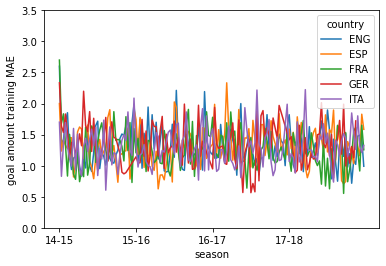

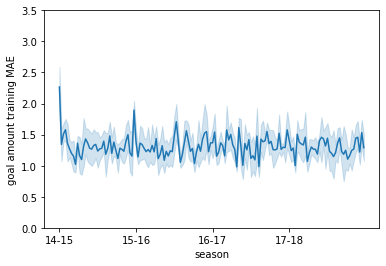

In [27]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("goal amount training MAE")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("goal amount training MAE")
plt.show()


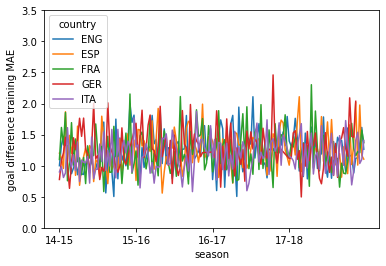

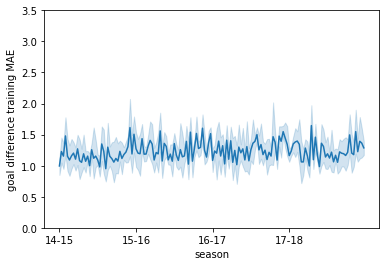

In [28]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("goal difference training MAE")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("goal difference training MAE")
plt.show()
